# Detecting Exoplanets in Kepler Transit Data

NASA's Kepler mission watched about 150,000 stars for four years, measuring the
brightness of each one every 30 minutes.

When a planet passes in front of its star, it blocks a little of the light. The star dims
slightly, then returns to normal, and it repeats every orbit. That repeating dip is called
a transit, and it is how Kepler found planets. Kepler's software flagged more than 9,500
of these dips as Kepler Objects of Interest, or KOIs.

About half of them were not planets. The usual culprit is an **eclipsing binary**: two
stars orbiting each other. A star is much bigger than a planet, so a full stellar eclipse
blocks far too much light to be mistaken for one. But there are two ways it can fool you:

- The two stars barely clip each other, so only a sliver of light is blocked.
- The pair sits far behind the target star. Their deep eclipse gets diluted by all the
  light from the bright foreground star, and what reaches us looks shallow.

This notebook builds a classifier that tells real planets apart from these impostors,
using measurements of the dip and of the star it happened on. It then does the same
measurements from scratch, starting from the raw brightness data.

**Contents**

1. Setup
2. Getting and labelling the data
3. Exploring the data
4. Feature engineering
5. Splitting into training and test sets
6. Comparing four models
7. Evaluating on held-out data
8. Choosing a decision threshold
9. Understanding what the model learned
10. From raw light curve to prediction
11. Conclusions

**Data.** The KOI table from the NASA Exoplanet Archive, plus raw brightness measurements
from the Mikulski Archive for Space Telescopes. Both download on first run and are cached
under `data/`, so later runs work offline.

## 1. Setup

Supporting code lives in `src/keplerml/` so this notebook can stay focused on the
analysis rather than on boilerplate. `config` holds paths and settings, `data` and
`features` prepare the table, `modeling` builds and scores the models, `lightcurves`
handles the raw brightness data, and `viz` draws the figures.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Allow the notebook to run from the repository root or from notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import keplerml as km
from keplerml import config, data, features, lightcurves, modeling, viz

warnings.filterwarnings("ignore", category=FutureWarning)
viz.set_plot_style()


pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

np.random.seed(config.RANDOM_STATE)

print(f"keplerml {km.__version__}")
print(f"project root      {PROJECT_ROOT}")
print(f"random seed       {config.RANDOM_STATE}")
print(f"cross-validation  {config.CV_FOLDS}-fold, grouped by host star")

keplerml 1.0.0
project root      /Users/devenshah/repos/kepler-exoplanets
random seed       42
cross-validation  5-fold, grouped by host star


## 2. Getting and labelling the data

The KOI table comes from the NASA Exoplanet Archive. It has one row per candidate signal
and 153 columns. The download asks only for the columns this project uses, which are
listed in `config.ARCHIVE_COLUMNS`. Naming them explicitly means that if the archive ever
renames a column, the download fails with an error instead of quietly handing back a
column full of blanks.

In [2]:
koi = data.load_koi_table()

print(f"rows     {len(koi):,}")
print(f"columns  {koi.shape[1]}")
print(f"cached   {config.KOI_TABLE_PATH.relative_to(PROJECT_ROOT)}")
print()
print(koi["koi_disposition"].value_counts().to_string())

rows     9,564
columns  39
cached   data/raw/koi_cumulative.csv

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2747
CANDIDATE         1978


In [3]:
koi[["kepoi_name", "kepler_name", "koi_disposition", "koi_period",
     "koi_duration", "koi_depth", "koi_prad", "koi_model_snr"]].head(8)

,kepoi_name,kepler_name,koi_disposition,koi_period,koi_duration,koi_depth,koi_prad,koi_model_snr
0,K00752.01,Kepler-227 b,CONFIRMED,9.488,2.958,615.800,2.260,35.800
1,K00752.02,Kepler-227 c,CONFIRMED,54.418,4.507,874.800,2.830,25.800
2,K00753.01,NaN,CANDIDATE,19.899,1.782,"10,829.000",14.600,76.300
3,K00754.01,NaN,FALSE POSITIVE,1.737,2.406,"8,079.200",33.460,505.600
4,K00755.01,Kepler-664 b,CONFIRMED,2.526,1.655,603.300,2.750,40.900
5,K00756.01,Kepler-228 d,CONFIRMED,11.094,4.595,"1,517.500",3.900,66.500
6,K00756.02,Kepler-228 c,CONFIRMED,4.134,3.140,686.000,2.770,40.200
7,K00756.03,Kepler-228 b,CONFIRMED,2.567,2.429,226.500,1.590,15.000


### 2.1 Defining the target

The column `koi_disposition` holds the verdict on each signal, and it takes three values:

- **CONFIRMED**: astronomers followed up and established it is a real planet.
- **FALSE POSITIVE**: they traced the dip to something else, usually an eclipsing binary.
- **CANDIDATE**: still undecided.

This is a two-class problem, so the CANDIDATE rows are dropped. Nobody knows the right
answer for them yet, so including them would mean training on guesses and grading against
guesses.

signals kept        7,586
  real planets      2,747  (36.2%)
  false positives   4,839
undecided, dropped  1,978


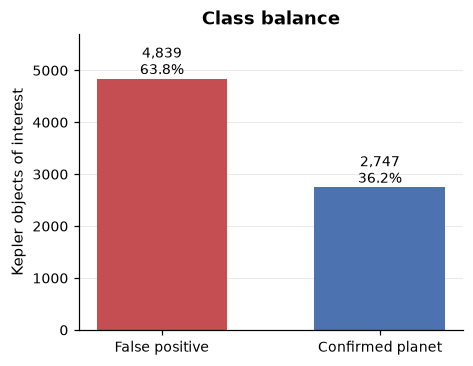

In [4]:
labeled = data.build_labeled_frame(koi)

print(f"signals kept        {len(labeled):,}")
print(f"  real planets      {int(labeled['label'].sum()):,}  ({labeled['label'].mean():.1%})")
print(f"  false positives   {int((1 - labeled['label']).sum()):,}")
print(f"undecided, dropped  {(koi['koi_disposition'] == 'CANDIDATE').sum():,}")

fig = viz.plot_class_balance(labeled["label"])
viz.save_figure(fig, "01_class_balance")
plt.show()

### 2.2 Checking for leakage

Data leakage is when a feature secretly contains the answer. The model scores well but has
learned nothing useful, and it falls apart on genuinely new data.

The KOI table has exactly this trap built in. Alongside the measurements, it ships the
notes NASA's own review process took while deciding each verdict. Four columns flag which
checks a signal failed, and `koi_score` records how confident the reviewer was. These are
not measurements of the dip. They are a record of someone already reaching the conclusion
we are trying to predict.

The cell below shows how badly this leaks, which is why these columns are excluded
everywhere in this notebook.

In [5]:
from sklearn.metrics import roc_auc_score

flag_columns = ["koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
any_flag = labeled[flag_columns].max(axis=1)

print("If we cheat and use only the review notes, with no measurements at all:")
print(f"  guessing 'planet' whenever no flag was raised  {(any_flag == 1 - labeled['label']).mean():.1%} correct")

scored = labeled.dropna(subset=["koi_score"])
print(f"  ranking candidates by koi_score               {roc_auc_score(scored['label'], scored['koi_score']):.3f} ROC AUC")
print()
print(f"So these {len(config.LEAKAGE_COLUMNS)} columns are excluded everywhere:")
print("  " + ", ".join(config.LEAKAGE_COLUMNS))

If we cheat and use only the review notes, with no measurements at all:
  guessing 'planet' whenever no flag was raised  98.5% correct
  ranking candidates by koi_score               0.984 ROC AUC

So these 11 columns are excluded everywhere:
  koi_disposition, koi_pdisposition, koi_score, koi_fpflag_nt, koi_fpflag_ss, koi_fpflag_co, koi_fpflag_ec, koi_vet_stat, koi_vet_date, koi_comment, koi_disp_prov


Near-perfect scores, from columns that contain no measurement of the star or the dip. Any
model trained with these would look excellent and be worthless. They stay out from here
on, and `data.check_for_leakage` raises an error if one ever slips into a feature list.

### 2.3 One star, several signals

A single star can produce more than one KOI, because it can host more than one planet.
That matters for splitting the data.

Stars with several signals are much more likely to be real planetary systems. A star
showing two independent, regular dips is almost certainly not an eclipsing binary. So if
one signal from a star ends up in training and another ends up in the test set, the model
can recognise the star instead of judging the dip, and the test score comes out too high.

Every split below therefore keeps all signals from a given star together, grouping on
`kepid`, the star's catalog ID.

In [6]:
per_star = labeled.groupby("kepid").size()

print(f"signals            {len(labeled):,}")
print(f"stars              {labeled['kepid'].nunique():,}")
print(f"stars with 2 or more signals   {(per_star > 1).sum():,}")
print(f"most signals on one star       {per_star.max()}")
print()
print("Share that turned out to be real planets:")
by_multiplicity = (
    labeled.assign(signals_on_star=labeled["kepid"].map(per_star).clip(upper=4))
    .groupby("signals_on_star")["label"]
    .agg(["size", "mean"])
    .rename(columns={"size": "signals", "mean": "share_confirmed"})
)
print(by_multiplicity.to_string())

signals            7,586
stars              6,640
stars with 2 or more signals   651
most signals on one star       7

Share that turned out to be real planets:
                 signals  share_confirmed
signals_on_star                          
1                   5989            0.240
2                    900            0.723
3                    399            0.942
4                    298            0.946


The trend is steep. A star with a single signal is confirmed 24 percent of the time. A
star with three or more is confirmed over 94 percent of the time. That is a strong hint
the model could exploit if the same star appeared on both sides of the split, so it will
not be allowed to.

## 3. Exploring the data

Three questions before building anything: how much data is missing, can the two classes
be told apart from the raw measurements, and what shape are the distributions.

In [7]:
measurement_columns = (
    config.TRANSIT_COLUMNS + config.DERIVED_PLANET_COLUMNS + config.STELLAR_COLUMNS
)
missing = data.summarize_missingness(labeled, measurement_columns)
missing[missing["missing"] > 0]

,missing,missing_pct
koi_bin_oedp_sig,910,12.000
koi_num_transits,681,8.980
koi_max_sngle_ev,681,8.980
koi_max_mult_ev,681,8.980
koi_smet,279,3.680
koi_incl,260,3.430
koi_dor,259,3.410
koi_impact,259,3.410
koi_model_snr,259,3.410
koi_ror,259,3.410


Nothing is missing more than about 13 percent of the time, and most columns are nearly
complete. Gaps are filled with the median of each column, computed inside the modelling
pipeline so it only ever uses training data.

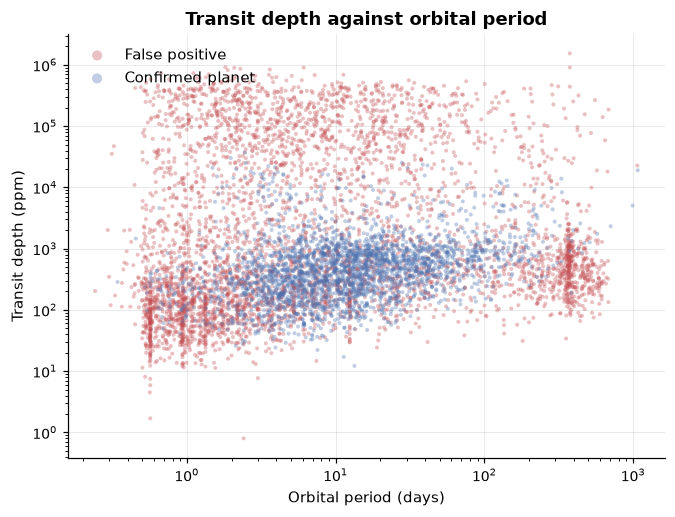

In [8]:
fig = viz.plot_period_depth(labeled)
viz.save_figure(fig, "02_period_depth")
plt.show()

Depth is measured in parts per million. A depth of 10,000 ppm means the star dimmed by one
percent.

The two groups overlap heavily, but they are not the same. False positives take over above
roughly 10,000 ppm, where whatever is blocking the light is simply too big to be a planet.
Real planets cluster at shorter periods and shallower depths. Neither axis separates the
classes on its own, and that is exactly why this needs a model rather than a cutoff.

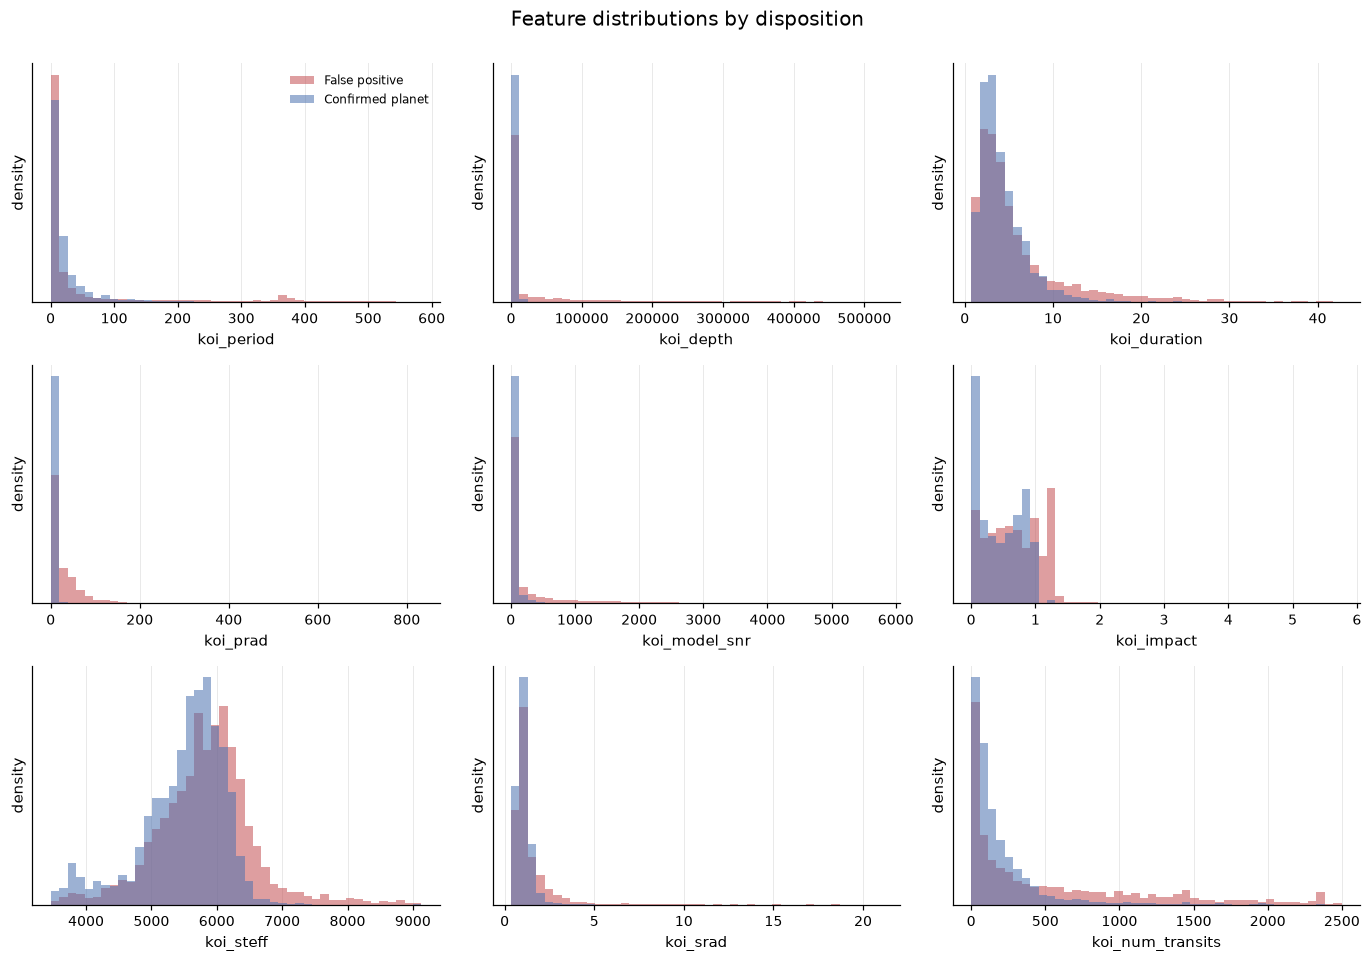

In [9]:
fig = viz.plot_feature_distributions(
    labeled,
    ["koi_period", "koi_depth", "koi_duration", "koi_prad",
     "koi_model_snr", "koi_impact", "koi_steff", "koi_srad", "koi_num_transits"],
)
viz.save_figure(fig, "03_feature_distributions")
plt.show()

Most of these are bunched hard against zero with a long tail to the right. Orbital period
runs from under a day to hundreds of days, and depth spans six orders of magnitude. Some
of the models coming up measure distances between points, and a single huge value would
dominate every such distance. The next section puts these on a log scale to fix that.

## 4. Feature engineering

Two changes to the table. First, the skewed columns get replaced by their base 10
logarithm, so a spread of six orders of magnitude becomes a spread of six.

Second, four new columns are added. Each one is a check an astronomer would do by hand,
written as a ratio so the model can use it.

| New feature | What it is | Why it helps |
| --- | --- | --- |
| `log_duty_cycle` | how much of each orbit the dip lasts | A planet crossing its star blocks light for a tiny slice of the orbit. Two stars clipping each other take much longer. |
| `log_duration_ratio` | how long the dip lasted, against how long it should have lasted given the orbit | These should agree. When they do not, the fitted orbit and the observed dip are telling different stories. |
| `log_density_ratio` | the star's density implied by the dip's shape, against its density from the catalog | The shape of a transit reveals how dense the star is. If that disagrees with what we know about the star, something is wrong. |
| `log_snr_per_transit` | how strong a single dip is, on average | Distinguishes one overwhelming event from many faint ones that only add up to something when combined. |

The model uses 27 features in total: the transit measurements, properties of the planet
and the star, and these four ratios.

The table also carries three columns that check *where on the detector* the dip came from,
which catches a nearby star bleeding into the measurement. Those are left out, because
this project is about what the shape of the dip can tell us.

In [10]:
engineered = features.add_engineered_features(labeled)
engineered, renames = features.apply_log_transforms(engineered)
feature_sets = features.build_feature_sets(renames)

for columns in feature_sets.values():
    data.check_for_leakage(columns)
print(f"{len(feature_sets['physical'])} features, leakage check passed")

print()
print("The four new features, typical value in each class")
class_medians = (
    engineered.groupby("label")[features.ENGINEERED_COLUMNS]
    .median()
    .T.rename(columns={0: "false positive", 1: "confirmed"})
)
class_medians["separation"] = class_medians["false positive"] - class_medians["confirmed"]
print(class_medians.to_string())

print()
duty_cycle = 10 ** engineered["log_duty_cycle"]
print("Share of the orbit spent dimming, typical value:")
print(f"  false positives  {100 * duty_cycle[engineered['label'] == 0].median():.1f}% of the orbit")
print(f"  real planets     {100 * duty_cycle[engineered['label'] == 1].median():.1f}% of the orbit")

27 features, leakage check passed

The four new features, typical value in each class
label                false positive  confirmed  separation
log_duty_cycle               -1.472     -1.889       0.417
log_duration_ratio           -0.019     -0.028       0.009
log_density_ratio            -0.236     -0.004      -0.232
log_snr_per_transit           0.556      0.499       0.057

Share of the orbit spent dimming, typical value:
  false positives  3.4% of the orbit
  real planets     1.3% of the orbit


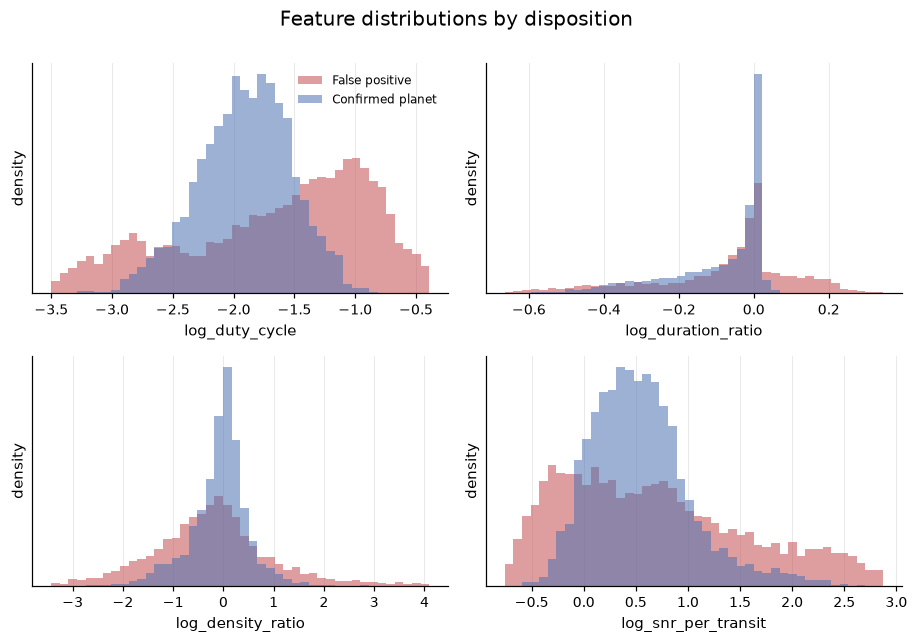

In [11]:
fig = viz.plot_feature_distributions(
    engineered, features.ENGINEERED_COLUMNS, n_cols=2
)
viz.save_figure(fig, "04_engineered_features")
plt.show()

Two of the four split the classes the way the physics says they should.

Real planets dim their star for about 1.3 percent of each orbit. False positives take
about 3.4 percent, more than twice as long. And the density ratio for real planets sits
essentially at 1, meaning the shape of the dip agrees with what we know about the star.
For false positives it does not.

The duration ratio barely separates the classes by itself, but it still earns a spot in
the importance ranking in section 9, which is a good reminder that a feature can be useful
in combination even when it looks flat on its own.

One thing to keep in mind for later: many of these columns are close relatives. Planet
radius is calculated from depth and star size, so the two move together almost perfectly.
That does not stop the models from working, but it does make "which feature mattered most"
a harder question than it sounds, and section 9 comes back to it.

## 5. Splitting into training and test sets

Twenty percent of the data is set aside as a test set and not touched again until section
7. Everything before that, including model selection, uses the other 80 percent.

`StratifiedGroupKFold` handles the split. It does two things at once: it keeps the same
mix of planets and false positives on both sides, and it keeps every signal from a given
star together, which is the rule from section 2.3. The assertion below confirms no star
ended up on both sides.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold

FEATURE_SET = "physical"
feature_names = feature_sets[FEATURE_SET]

X_all = engineered[feature_names]
y_all = engineered["label"].to_numpy()
groups_all = engineered["kepid"].to_numpy()

holdout_splitter = StratifiedGroupKFold(
    n_splits=int(round(1 / config.TEST_SIZE)), shuffle=True, random_state=config.RANDOM_STATE
)
train_index, test_index = next(holdout_splitter.split(X_all, y_all, groups_all))

X_train, y_train, groups_train = X_all.iloc[train_index], y_all[train_index], groups_all[train_index]
X_test, y_test = X_all.iloc[test_index], y_all[test_index]

cv = StratifiedGroupKFold(
    n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE
)

shared_stars = set(groups_all[train_index]) & set(groups_all[test_index])
assert not shared_stars, "a host star appears in both the training and test sets"

print(f"features                  {len(feature_names)}")
print(f"training signals          {len(X_train):,}  ({y_train.mean():.1%} real planets)")
print(f"test signals              {len(X_test):,}  ({y_test.mean():.1%} real planets)")
print(f"stars in both halves      {len(shared_stars)}")

features                  27
training signals          6,069  (36.2% real planets)
test signals              1,517  (36.2% real planets)
stars in both halves      0


## 6. Comparing four models

Four classifiers, each one trying to draw the boundary between planets and false
positives in a different way:

- **Logistic regression** draws a single straight boundary. A simple baseline.
- **k-nearest neighbours** classifies each signal by looking at the most similar signals
  it saw during training.
- **Random forest** builds hundreds of decision trees full of cutoffs like "depth above
  10,000 ppm" and takes a vote.
- **Support vector machine** draws one smooth curved boundary.

Each sits in a pipeline that fills missing values and rescales the features first. Putting
those steps inside the pipeline matters: it means they are recalculated from scratch for
every fold, so no fold is ever prepared using information from the data it will be tested
on.

Each model's settings are tuned by trying every combination on a grid and keeping the best,
scored by **ROC AUC**. That measures how well a model *ranks*: pick one real planet and one
false positive at random, and ROC AUC is the chance the model scored the planet higher.
1.0 is perfect, 0.5 is a coin flip. Ranking is the right thing to optimise here because
the cutoff for calling something a planet is a separate decision, made in section 8.

In [13]:
specifications = modeling.model_specifications()
search_results = []

for name, specification in specifications.items():
    result = modeling.run_model_search(name, specification, X_train, y_train, groups_train, cv)
    search_results.append(result)
    print(f"{name:24s} ROC AUC {result.cv_scores['roc_auc']:.3f}  "
          f"({result.fit_seconds:5.1f}s)  best settings: {result.best_params}")

Logistic Regression      ROC AUC 0.960  (  3.0s)  best settings: {'C': 100.0}


k-Nearest Neighbors      ROC AUC 0.973  (  1.5s)  best settings: {'n_neighbors': 21, 'p': 1, 'weights': 'distance'}


Random Forest            ROC AUC 0.980  ( 63.8s)  best settings: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}


Support Vector Machine   ROC AUC 0.980  (  3.0s)  best settings: {'C': 10.0, 'gamma': 'scale'}


In [14]:
from sklearn.base import clone

best_result = max(search_results, key=lambda result: result.cv_scores["roc_auc"])
print(f"Best model: {best_result.name}\n")

cv_summary = modeling.summarize_searches(search_results)
cv_summary[["roc_auc", "roc_auc_std", "average_precision", "f1"]]

Best model: Support Vector Machine



,roc_auc,roc_auc_std,average_precision,f1
model,,,,
Support Vector Machine,0.980,0.004,0.965,0.909
Random Forest,0.980,0.002,0.962,0.900
k-Nearest Neighbors,0.973,0.003,0.948,0.884
Logistic Regression,0.960,0.005,0.920,0.865


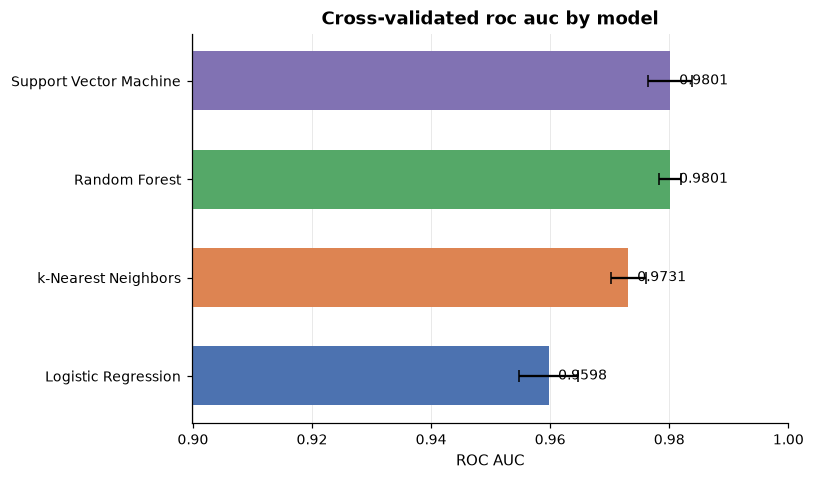

In [15]:
fig = viz.plot_cv_comparison(cv_summary)
viz.save_figure(fig, "05_cv_comparison")
plt.show()

The order makes sense given how each model works.

Logistic regression comes last because one straight line cannot capture the problem. Some
features only mean something in combination: a long dip is suspicious, but only if it is
also deep. A straight boundary cannot express "only if".

k-nearest neighbours does better, but it has to treat all 27 features as equally
important when deciding what counts as similar, and they are not.

The random forest and the support vector machine finish essentially tied, reaching the
same place by different routes. The forest stacks up physical cutoffs. The support vector
machine bends one smooth boundary around the data. The error bars show how much the score
moved between folds, and the gap between the top two is smaller than that, so this is a
tie rather than a win.

## 7. Evaluating on held-out data

Now the test set gets used, once. It has been untouched through feature engineering and
model selection, so these numbers are the honest estimate of how each model would do on
signals it has never seen.

Two of the columns below are worth naming. **Precision** is the share of signals the model
called planets that really were planets. **Recall** is the share of real planets it
managed to find.

In [16]:
test_metrics = {}
test_scores = {}

for result in search_results:
    test_metrics[result.name] = modeling.evaluate(result.best_estimator, X_test, y_test)
    test_scores[result.name] = modeling.predicted_scores(result.best_estimator, X_test)

test_summary = pd.DataFrame(test_metrics).T.sort_values("roc_auc", ascending=False)
test_summary[["roc_auc", "accuracy", "precision", "recall", "f1"]]

,roc_auc,accuracy,precision,recall,f1
Support Vector Machine,0.981,0.938,0.896,0.938,0.916
Random Forest,0.977,0.934,0.906,0.913,0.909
k-Nearest Neighbors,0.968,0.906,0.830,0.933,0.878
Logistic Regression,0.957,0.891,0.802,0.927,0.860


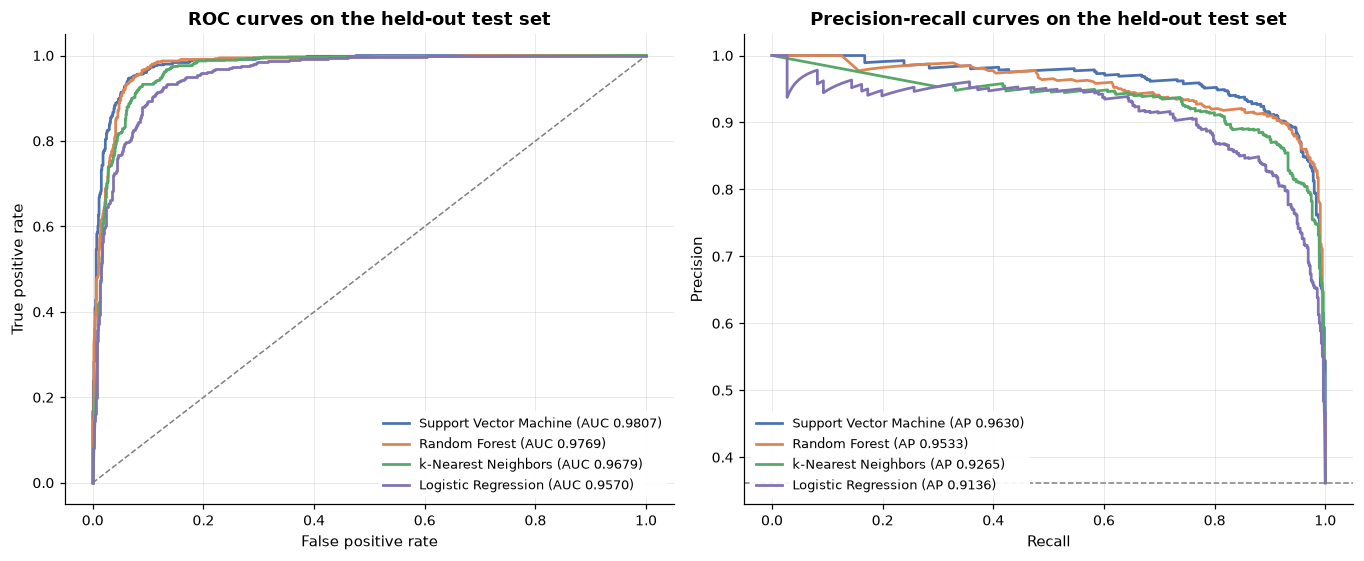

In [17]:
ordered_names = list(test_summary.index)
ordered_scores = {name: test_scores[name] for name in ordered_names}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
viz.plot_roc_curves(y_test, ordered_scores, ax=axes[0])
viz.plot_pr_curves(y_test, ordered_scores, ax=axes[1])
fig.tight_layout()
viz.save_figure(fig, "06_roc_pr")
plt.show()

The test scores land almost exactly where cross-validation predicted, which is the main
thing to check here. It means the grouped split held and the tuning did not quietly overfit.

The left panel is the ROC curve, and the area under it is the ROC AUC from section 6. The
right panel is precision against recall, and it is the more useful of the two for this
problem. It ignores credit for correctly rejecting false positives, which are the majority
class, so it shows the real cost of chasing the last few planets.

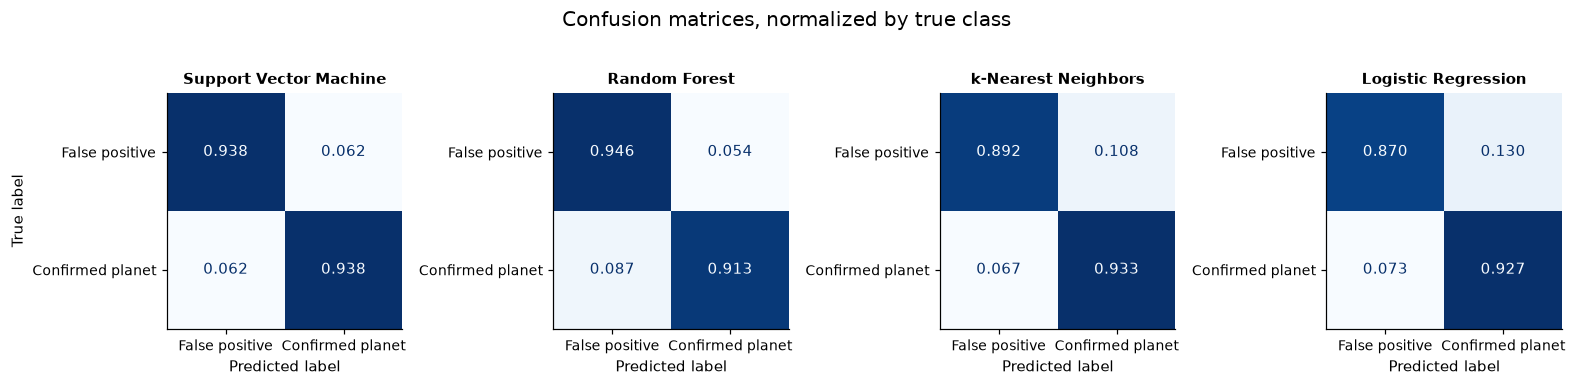

In [18]:
test_predictions = {
    name: (test_scores[name] >= 0.5).astype(int) for name in ordered_names
}
fig = viz.plot_confusion_matrices(y_test, test_predictions)
viz.save_figure(fig, "07_confusion_matrices")
plt.show()

Each panel reads left to right by true class. The top row is the false positives: the left
number is the share correctly rejected, the right number is the share wrongly called
planets. The bottom row is the real planets, and the right number is the share correctly
found.

## 8. Choosing a decision threshold

The model outputs a score between 0 and 1. Everything so far has called anything above 0.5
a planet, which quietly assumes that missing a real planet and raising a false alarm are
equally bad.

For a real survey they are not. Confirming a candidate means booking time on a large
telescope, and that time is scarce. A shorter list you can trust beats a longer list full
of dead ends.

So the threshold gets raised until the model is right 95 percent of the time when it says
"planet". The question is how many real planets that costs. The threshold is picked using
the training data only, never the test set.

model             Support Vector Machine
target precision  95% of predicted planets should be real
threshold needed  0.769  (instead of 0.5)
planets found     82.4%  (estimated from training data)


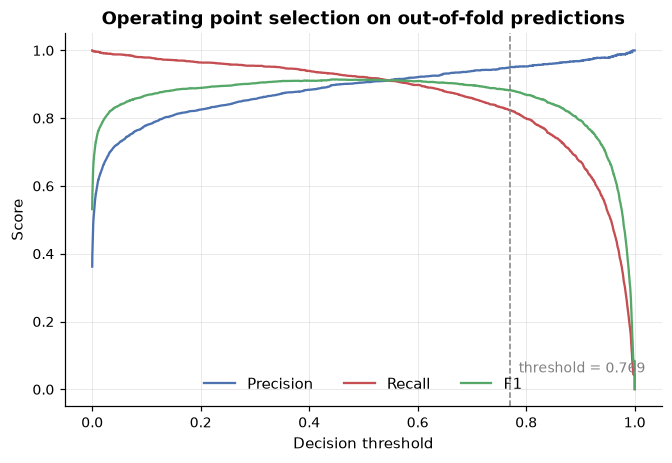

In [19]:
TARGET_PRECISION = 0.95

oof_scores = modeling.out_of_fold_scores(
    clone(best_result.best_estimator), X_train, y_train, groups_train, cv
)
threshold, expected_recall = modeling.threshold_for_precision(
    y_train, oof_scores, TARGET_PRECISION
)

print(f"model             {best_result.name}")
print(f"target precision  {TARGET_PRECISION:.0%} of predicted planets should be real")
print(f"threshold needed  {threshold:.3f}  (instead of 0.5)")
print(f"planets found     {expected_recall:.1%}  (estimated from training data)")

fig = viz.plot_threshold_tradeoff(y_train, oof_scores, threshold)
viz.save_figure(fig, "08_threshold")
plt.show()

In [20]:
default_metrics = modeling.evaluate(best_result.best_estimator, X_test, y_test, threshold=0.5)
tuned_metrics = modeling.evaluate(best_result.best_estimator, X_test, y_test, threshold=threshold)

comparison = pd.DataFrame(
    {"threshold 0.500": default_metrics, f"threshold {threshold:.3f}": tuned_metrics}
).loc[["precision", "recall", "f1", "accuracy"]]
comparison

,threshold 0.500,threshold 0.769
precision,0.896,0.936
recall,0.938,0.854
f1,0.916,0.893
accuracy,0.938,0.926


This is the trade in plain terms. Raising the threshold makes the model more careful, so a
larger share of its "planet" calls are correct, but it also stays quiet on some real
planets and misses them.

Worth being honest about one thing: the target was 95 percent precision, and on the test
set it comes out slightly below that. The miss is about the size of the fold-to-fold
wobble seen in section 6, so the threshold is a good estimate rather than a guarantee.

Where to sit on this curve is not a modelling decision. It depends on how much telescope
time a wasted follow-up costs.

## 9. Understanding what the model learned

Permutation importance works by breaking one feature at a time. Shuffle a column so its
values no longer line up with the right rows, re-score the model, and see how much worse
it got. A big drop means the model was leaning on that column.

Drop in ROC AUC when each feature is shuffled
log_max_sngle_ev     0.169
log_model_snr        0.082
log_max_mult_ev      0.068
log_num_transits     0.059
log_ror              0.033
log_dor              0.033
log_prad             0.031
log_duration_ratio   0.025


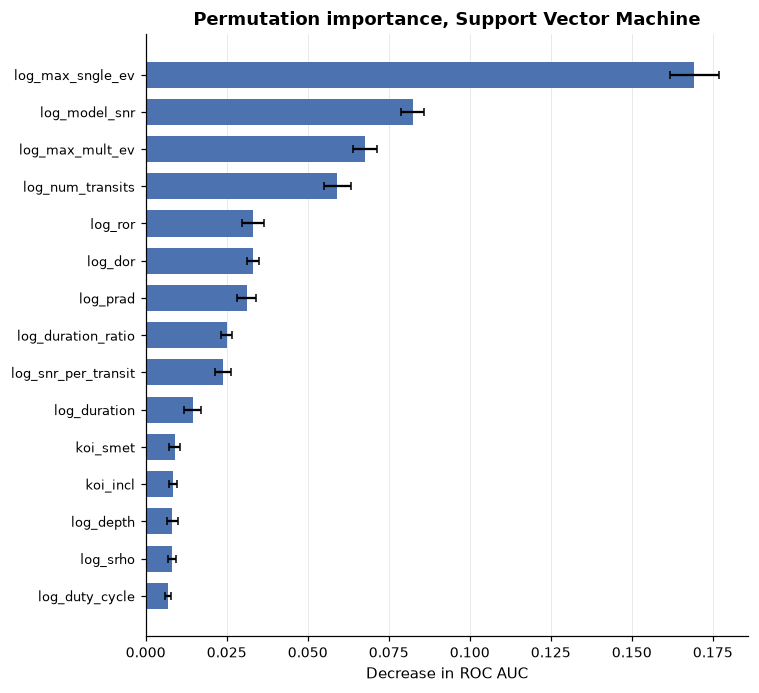

In [21]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_result.best_estimator,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=config.RANDOM_STATE,
    n_jobs=-1,
)

importance_mean = pd.Series(importance.importances_mean, index=feature_names)
importance_std = pd.Series(importance.importances_std, index=feature_names)

ranked = importance_mean.sort_values(ascending=False)
print("Drop in ROC AUC when each feature is shuffled")
print(ranked.head(8).to_string())

top = ranked.head(15)
fig = viz.plot_importances(
    top, importance_std.reindex(top.index), title=f"Permutation importance, {best_result.name}"
)
viz.save_figure(fig, "09_permutation_importance")
plt.show()

The top of the list is dominated by measures of signal strength, and the reason is more
interesting than it looks.

`log_max_sngle_ev` describes the strongest individual dip. `log_max_mult_ev` and
`log_model_snr` describe how strong the dips are once all of them are added together. A
planet produces many faint dips that only become convincing in combination. Two stars
eclipsing each other produce dips that are already unmistakable one at a time.

So the model is not really reading any one of those three numbers. It is reading how they
compare, which is the same comparison `log_snr_per_transit` was designed to make directly.

Below those sit the size measurements, which is the blunter test: whatever caused the dip
is simply too big to be a planet.

The table below confirms each effect points the way it should, by comparing the typical
value in each class.

In [22]:
directional = engineered.iloc[test_index].groupby("label")[list(ranked.head(6).index)].median().T
directional.columns = ["false positive", "real planet"]
directional["higher_in"] = np.where(
    directional["false positive"] > directional["real planet"], "false positives", "real planets"
)
directional

,false positive,real planet,higher_in
log_max_sngle_ev,0.918,0.759,false positives
log_model_snr,1.521,1.461,false positives
log_max_mult_ev,1.389,1.375,false positives
log_num_transits,2.415,2.025,false positives
log_ror,-1.334,-1.697,false positives
log_dor,0.917,1.317,real planets


Every row points the way the physics says it should. False positives are bigger relative
to their star, produce stronger individual dips, and get observed more often, because a
pair of stars orbiting each other every day or two is both easy to spot and easy to spot
repeatedly.

One caveat on reading this ranking. Back in section 4 the point came up that many of these
columns are close relatives. Permutation importance breaks one column at a time, so when
two columns say nearly the same thing, breaking either one costs almost nothing and both
look unimportant. `log_duty_cycle` is the clearest victim: it separates the classes
cleanly on its own, but it ranks low here because duration and period between them can
rebuild it. Low importance means "not needed given everything else", not "not useful".

### 9.1 Where the model fails

The mistakes say more than the headline score does.

In [23]:
test_frame = engineered.iloc[test_index].copy()
test_frame["score"] = test_scores[best_result.name]
test_frame["correct"] = (test_frame["score"] >= 0.5).astype(int) == test_frame["label"]

errors = test_frame[~test_frame["correct"]]
print(f"got {len(errors)} of {len(test_frame)} test signals wrong ({len(errors) / len(test_frame):.1%})")
print(f"  real planets dismissed        {int((errors['label'] == 1).sum())}")
print(f"  false positives let through   {int((errors['label'] == 0).sum())}")
print()
print("Typical signal, split by whether the model got it right:")
(
    test_frame.groupby(["label", "correct"])[
        ["koi_depth", "koi_model_snr", "koi_prad"]
    ]
    .median()
    .rename(index={0: "false positive", 1: "real planet"}, level=0)
)

got 94 of 1517 test signals wrong (6.2%)
  real planets dismissed        34
  false positives let through   60

Typical signal, split by whether the model got it right:


koi_depth  koi_model_snr  koi_prad
label          correct                                    
false positive False      260.700         23.350     1.555
               True       734.550         37.550    15.825
real planet    False      203.200         16.650     1.510
               True       441.500         30.000     2.130

The mistakes are not scattered at random. In both classes, the ones the model gets wrong
are shallower and weaker than the ones it gets right, and both sit around one and a half
Earth radii. The model fails on small, faint, borderline signals.

The clearest case is the false positives. The ones it catches imply an object over ten
Earth radii, far too big to be a planet, so size alone gives them away. The ones it misses
imply under two Earth radii, so that giveaway is gone.

Those are mostly the diluted background binaries described at the top of this notebook,
where a bright foreground star washes out a deep stellar eclipse into something that looks
planet-sized. Nothing about the shape of the dip can catch them. That takes either the
detector-position columns this project deliberately set aside, or follow-up observations
from the ground.

## 10. From raw light curve to prediction

Everything so far started from a table where someone had already measured the period, the
depth, and the duration. This section measures them from scratch, starting from the raw
brightness readings.

The tool is a **Box Least Squares periodogram**. The idea is simple. Guess a period. Fold
the data on it, meaning cut the timeline into chunks of that length and stack them. If the
guess is right, every dip lands on top of every other dip and a clear notch appears. If the
guess is wrong, the dips scatter and average away. Try a hundred thousand guesses and keep
the one that produces the sharpest notch.

The steps are: download the brightness data, stitch the observing quarters together,
remove slow drift so the baseline is flat, scan the period range, then rescan finely
around the winner. Four targets, two real planets and two false positives.

In [24]:
DEMO_KOIS = ["K00001.01", "K00097.01", "K01542.01", "K07367.01"]

demo = koi[koi["kepoi_name"].isin(DEMO_KOIS)].set_index("kepoi_name").loc[DEMO_KOIS]
demo[["kepid", "kepler_name", "koi_disposition", "koi_period", "koi_depth",
      "koi_duration", "koi_prad", "koi_kepmag"]]

,kepid,kepler_name,koi_disposition,koi_period,koi_depth,koi_duration,koi_prad,koi_kepmag
kepoi_name,,,,,,,,
K00001.01,11446443,Kepler-1 b,CONFIRMED,2.471,"14,230.900",1.743,13.040,11.338
K00097.01,5780885,Kepler-7 b,CONFIRMED,4.885,"7,458.400",5.162,16.660,12.885
K01542.01,8113154,NaN,FALSE POSITIVE,2.587,"25,480.000",6.161,19.840,12.897
K07367.01,10736223,NaN,FALSE POSITIVE,1.105,"730,498.000",4.382,267.590,13.651


The first two are giant planets orbiting close to their stars, with clean, obvious
transits.

The false positives were picked to be different from each other. `K07367.01` blocks more
than half its star's light, which nothing but another star can do. `K01542.01` is the
harder one: at roughly 25,000 ppm it dims the star by 2.5 percent, which a very large
planet could plausibly manage. Depth alone will not settle it, and the folded light curve
will.

In [25]:
curves, flattened = {}, {}

for koi_name in DEMO_KOIS:
    target = f"KIC {int(demo.loc[koi_name, 'kepid'])}"
    curve = lightcurves.fetch_light_curve(target)
    curves[koi_name] = curve
    flattened[koi_name] = lightcurves.flatten_flux(curve)
    print(f"{koi_name}  {target:14s}  {curve.n_points:6,} cadences over "
          f"{curve.baseline_days:.0f} days  quarters {list(curve.quarters)}")

K00001.01  KIC 11446443    13,698 cadences over 368 days  quarters [2, 3, 4, 5]
K00097.01  KIC 5780885     16,797 cadences over 368 days  quarters [2, 3, 4, 5]
K01542.01  KIC 8113154     16,798 cadences over 368 days  quarters [2, 3, 4, 5]
K07367.01  KIC 10736223    16,798 cadences over 368 days  quarters [2, 3, 4, 5]


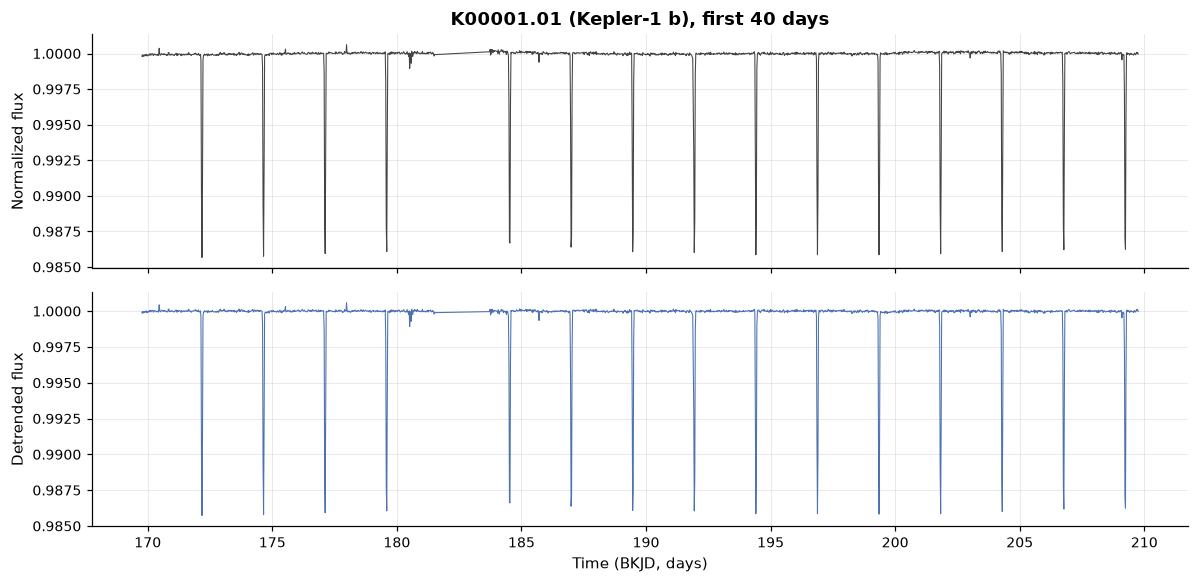

In [26]:
example = "K00001.01"
fig = viz.plot_light_curve(
    curves[example].time,
    curves[example].flux,
    flattened[example],
    title=f"{example} ({demo.loc[example, 'kepler_name']}), first 40 days",
)
viz.save_figure(fig, "10_light_curve")
plt.show()

The top panel is the raw brightness. The slow wandering is real: it is the star itself,
with dark spots rotating in and out of view as it turns, plus some drift from the
spacecraft. The transits are there as regular narrow dips, but they sit on a baseline that
keeps moving.

The bottom panel is the same data after removing that drift. The baseline is flat and the
dips are untouched, which is what the period search needs.

In [27]:
bls_objects, bls_results, bls_features = {}, {}, {}

for koi_name in DEMO_KOIS:
    bls, result = lightcurves.run_bls(curves[koi_name].time, flattened[koi_name])
    bls_objects[koi_name] = bls
    bls_results[koi_name] = result
    bls_features[koi_name] = lightcurves.transit_features(result)
    archive_period = demo.loc[koi_name, "koi_period"]
    print(f"{koi_name}  measured {result.period:9.5f} days   "
          f"NASA {archive_period:9.5f} days   off by {abs(result.period / archive_period - 1):.1e}")

K00001.01  measured   2.47062 days   NASA   2.47061 days   off by 2.2e-06


K00097.01  measured   4.88551 days   NASA   4.88549 days   off by 4.2e-06


K01542.01  measured   2.58690 days   NASA   2.58688 days   off by 6.8e-06


K07367.01  measured   1.10510 days   NASA   1.10509 days   off by 5.2e-06


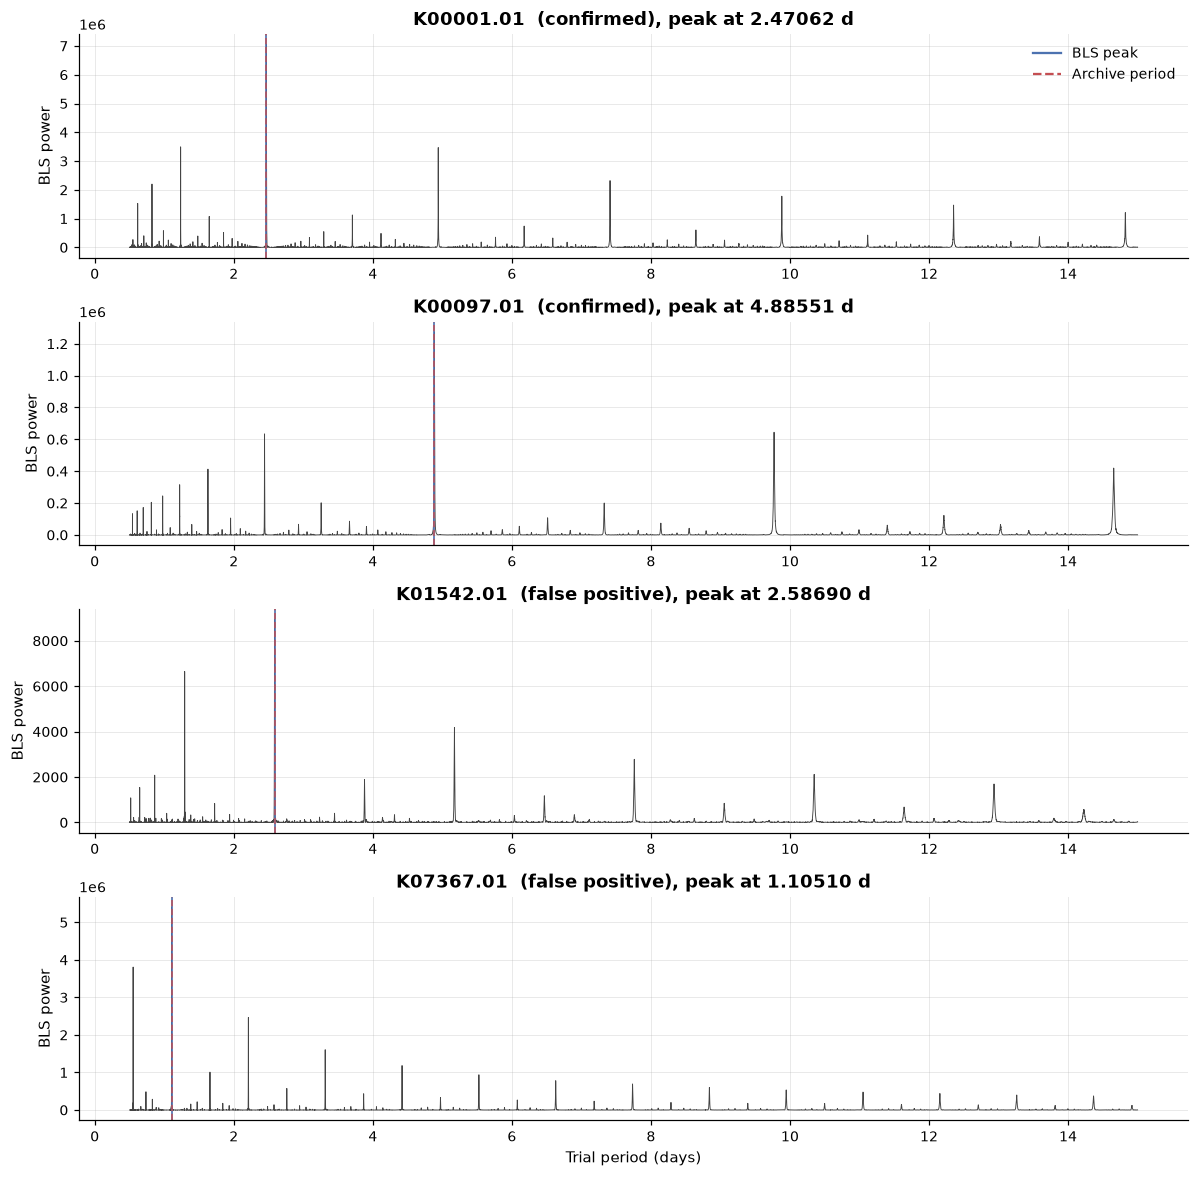

In [28]:
fig, axes = plt.subplots(len(DEMO_KOIS), 1, figsize=(11, 2.7 * len(DEMO_KOIS)))

for ax, koi_name in zip(axes, DEMO_KOIS):
    result = bls_results[koi_name]
    ax.plot(result.period_grid, result.power, color="#444444", linewidth=0.6)
    ax.axvline(result.period, color=viz.POSITIVE_COLOR, linewidth=1.3, alpha=0.85)
    ax.axvline(demo.loc[koi_name, "koi_period"], color=viz.NEGATIVE_COLOR,
               linestyle="--", linewidth=1.1, alpha=0.85)
    ax.set_ylabel("BLS power")
    ax.set_title(f"{koi_name}  ({demo.loc[koi_name, 'koi_disposition'].lower()}), "
                 f"peak at {result.period:.5f} d")

axes[-1].set_xlabel("Trial period (days)")
axes[0].legend(
    handles=[
        plt.Line2D([], [], color=viz.POSITIVE_COLOR, label="BLS peak"),
        plt.Line2D([], [], color=viz.NEGATIVE_COLOR, linestyle="--", label="Archive period"),
    ],
    loc="upper right",
    fontsize=9,
)
fig.tight_layout()
viz.save_figure(fig, "11_periodograms")
plt.show()

Each one has a single dominant spike, and it sits exactly on NASA's published period in
all four cases. The smaller spikes to the right are at two and three times the true period,
where folding still lines up every second or third dip and so scores partial credit.

Now fold on the recovered period and look at one full orbit. This is where the difference
between a planet and a pair of stars becomes visible to the eye.

Phase 0 is the middle of the dip. Phase 0.5 is exactly halfway round the orbit, marked
with a dotted line. The panels run from -0.25 to 0.75 rather than the more common -0.5 to
0.5 so that both of those points sit inside the plot instead of the halfway point being
sliced across the two edges.

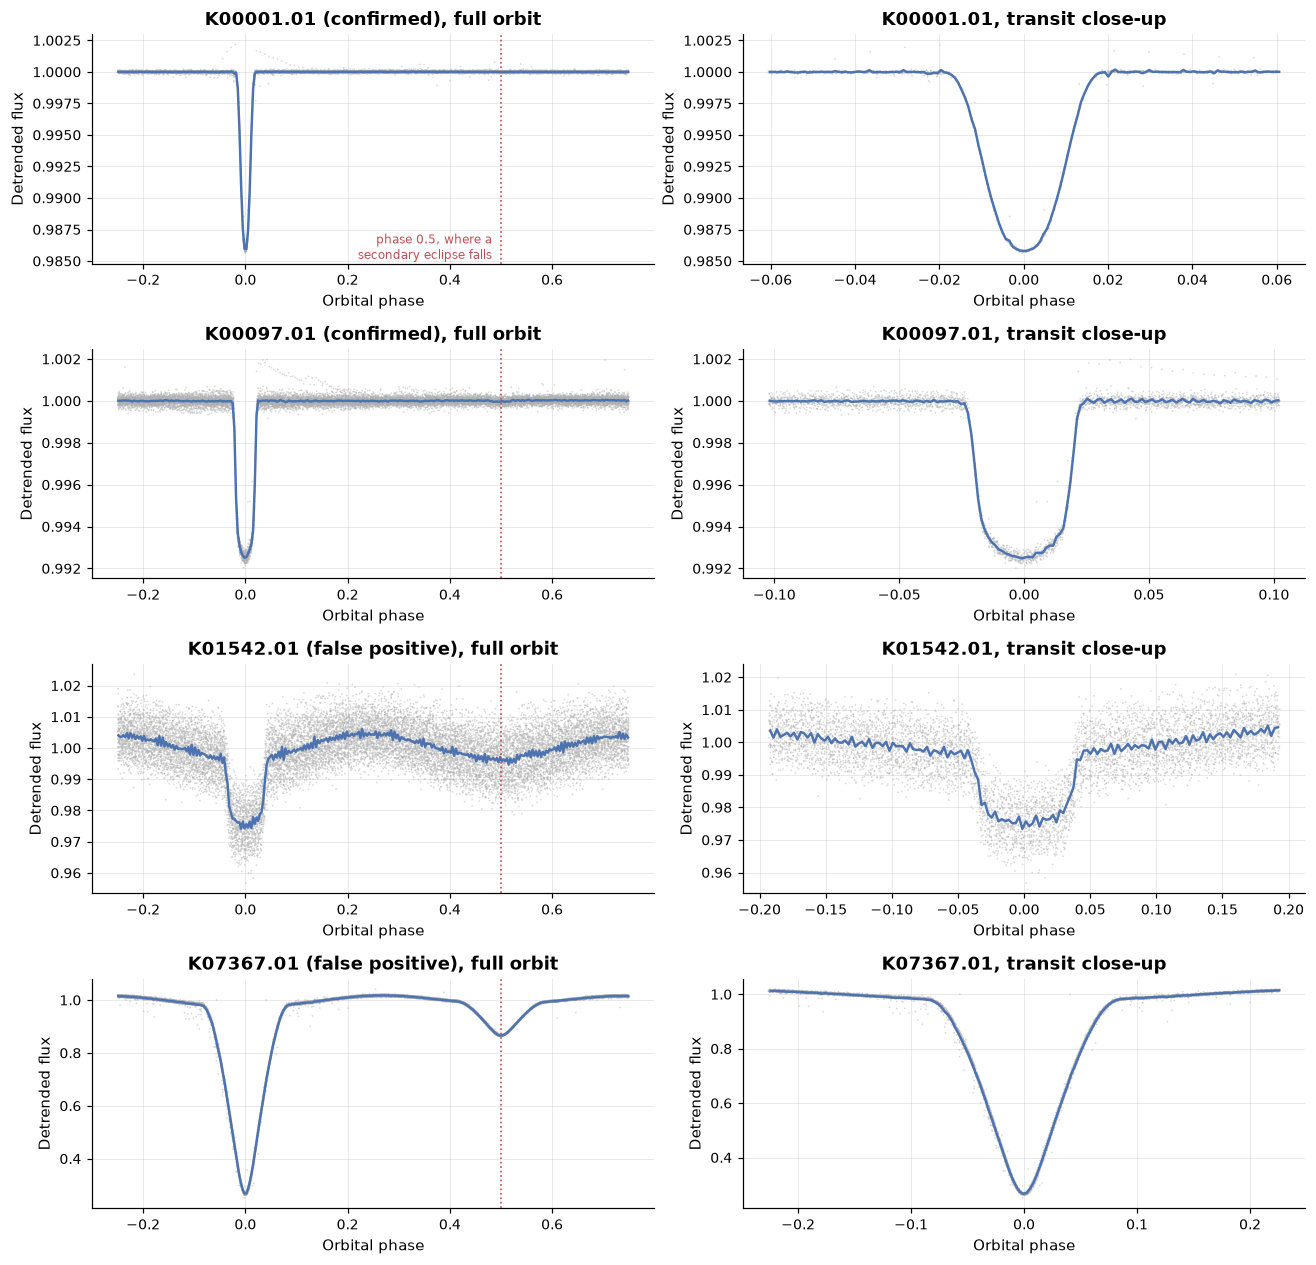

In [29]:
PHASE_MIN = -0.25

fig, axes = plt.subplots(len(DEMO_KOIS), 2, figsize=(12, 2.9 * len(DEMO_KOIS)))

for row, koi_name in enumerate(DEMO_KOIS):
    result = bls_results[koi_name]
    phase, flux = lightcurves.phase_fold(
        curves[koi_name].time, flattened[koi_name], result.period, result.t0,
        phase_min=PHASE_MIN,
    )
    disposition = demo.loc[koi_name, "koi_disposition"].lower()

    # The full-orbit panel needs coarse bins. The close-up needs enough bins to
    # resolve the transit, but not so many that each holds too few cadences to
    # average, so the count is scaled to give a fixed resolution inside the zoom.
    zoom = 2.5 * result.duration / result.period
    close_bins = int(np.clip(75 / zoom, 200, 2500))

    orbit_phase, orbit_flux = lightcurves.bin_phase(phase, flux, 300, PHASE_MIN)
    close_phase, close_flux = lightcurves.bin_phase(phase, flux, close_bins, PHASE_MIN)

    viz.plot_phase_fold(
        phase, flux, orbit_phase, orbit_flux,
        title=f"{koi_name} ({disposition}), full orbit", ax=axes[row, 0],
    )
    viz.plot_phase_fold(
        phase, flux, close_phase, close_flux,
        title=f"{koi_name}, transit close-up", ax=axes[row, 1], zoom=zoom,
    )
    axes[row, 0].axvline(0.5, color=viz.NEGATIVE_COLOR, linestyle=":", linewidth=1.1)

axes[0, 0].annotate(
    "phase 0.5, where a\nsecondary eclipse falls",
    xy=(0.5, 0.02), xycoords=("data", "axes fraction"),
    xytext=(-6, 0), textcoords="offset points",
    ha="right", fontsize=8, color=viz.NEGATIVE_COLOR,
)

fig.tight_layout()
viz.save_figure(fig, "12_phase_folds")
plt.show()

The left column settles it, including for `K01542.01`, which depth alone could not.

Both real planets are flat everywhere except at phase 0. Nothing at the dotted line,
nothing anywhere else.

Both false positives show a second, shallower dip right at the dotted line. That is the
companion going *behind* the bright star and having its own light blocked. A planet cannot
do this, because a planet gives off no meaningful light of its own to block.

There is a second tell in `K01542.01`: the brightness rises and falls smoothly between the
eclipses. Two stars this close pull each other into egg shapes, so the surface area facing
us changes as they orbit. A planet is nowhere near massive enough to distort its star that
way.

The right column zooms in on the dip itself. The planets have a gently rounded bottom,
because a star is brighter at its centre than at its edge, so the dip deepens as the planet
crosses the middle. `K07367.01` instead plunges to a sharp V, and `K01542.01` has the steep
straight walls of one star crossing another.

In [30]:
recovery = pd.DataFrame(
    {
        koi_name: {
            "depth_measured": bls_results[koi_name].depth_ppm,
            "depth_nasa": demo.loc[koi_name, "koi_depth"],
            "duration_measured": bls_results[koi_name].duration_hours,
            "duration_nasa": demo.loc[koi_name, "koi_duration"],
            "period_off_by_ppm": 1e6
            * abs(bls_results[koi_name].period / demo.loc[koi_name, "koi_period"] - 1),
        }
        for koi_name in DEMO_KOIS
    }
).T

recovery["depth_frac_of_nasa"] = recovery["depth_measured"] / recovery["depth_nasa"]
recovery["duration_frac_of_nasa"] = recovery["duration_measured"] / recovery["duration_nasa"]
recovery.round(3)

,depth_measured,depth_nasa,duration_measured,duration_nasa,period_off_by_ppm,depth_frac_of_nasa,duration_frac_of_nasa
K00001.01,"10,846.887","14,230.900",1.440,1.743,2.195,0.762,0.826
K00097.01,"6,463.079","7,458.400",4.800,5.162,4.176,0.867,0.930
K01542.01,"22,382.197","25,480.000",4.800,6.161,6.778,0.878,0.779
K07367.01,"504,225.617","730,498.000",2.400,4.382,5.160,0.690,0.548


Periods match NASA's to a few parts per million, which is just the spacing of the search
grid rather than any limit of the method.

Depths come out 15 to 30 percent shallow, and durations come out short. That is expected,
not a bug. The method fits a **box**, which is flat-bottomed with vertical sides. Real
transits are neither: they slope in and out as the planet crosses the edge of the star,
and the bottom is curved. A box has to average over all of that, so it settles a bit
shallower and a bit narrower than the true shape.

The bias is consistent and in a known direction, which is why a production pipeline uses
the box result as a starting point and then fits a realistic transit shape on top of it.

### 10.1 Turning the picture into numbers

The eye can see the difference in those plots. To be useful the pipeline has to measure it,
so the same fit gets rerun under two alternative assumptions.

**Secondary ratio** slides the box half an orbit over and measures how deep the dip is
there, as a fraction of the main dip. That is the second eclipse, put on a scale.

**Odd-even ratio** compares alternating dips. If they differ, the true period is really
twice what was found, and the dips are two different stars taking turns.

In [31]:
diagnostics = pd.DataFrame(bls_features).T
diagnostics.insert(0, "disposition", demo["koi_disposition"])
diagnostics[["disposition", "bls_depth_ppm", "bls_duty_cycle",
             "secondary_ratio", "odd_even_ratio"]]

,disposition,bls_depth_ppm,bls_duty_cycle,secondary_ratio,odd_even_ratio
K00001.01,CONFIRMED,"10,846.887",0.024,-0.001,0.002
K00097.01,CONFIRMED,"6,463.079",0.041,0.005,0.014
K01542.01,FALSE POSITIVE,"22,382.197",0.077,0.208,0.027
K07367.01,FALSE POSITIVE,"504,225.617",0.090,0.182,0.001


The secondary ratio splits the four targets apart cleanly. Both planets are under one
percent, which is indistinguishable from nothing. Both false positives are near 20 percent.
That single number, computed from the raw brightness data with no help from any catalog,
would have caught them both.

The odd-even ratio stays near zero for everything, including the two binaries. That is the
right answer, not a miss. It only fires when the two stars differ in brightness, and
neither of these pairs does. No single check catches every impostor, which is exactly the
argument for a model that combines many of them instead of thresholding on one.

The duty cycle lines up too: 8 to 9 percent for the false positives against 2 to 4 percent
for the planets, matching the pattern the full catalog showed back in section 4.

### 10.2 Closing the loop

Last step: hand the measurements to the trained classifier.

For each target, NASA's period, duration, depth, and transit count get swapped out for the
values measured in this section, and everything derived from them is recalculated. What
stays is anything the brightness data cannot determine on its own, mainly the star's mass,
radius, and temperature, which come from separate observations.

Then compare two predictions: one from NASA's row, one from the rebuilt row. If they agree,
the measurement step is good enough to feed the classifier.

In [32]:
rebuilt = koi[koi["kepoi_name"].isin(DEMO_KOIS)].set_index("kepoi_name").loc[DEMO_KOIS].copy()

for koi_name in DEMO_KOIS:
    measured = bls_features[koi_name]
    rebuilt.loc[koi_name, "koi_period"] = measured["bls_period"]
    rebuilt.loc[koi_name, "koi_duration"] = measured["bls_duration_hours"]
    rebuilt.loc[koi_name, "koi_depth"] = measured["bls_depth_ppm"]
    rebuilt.loc[koi_name, "koi_num_transits"] = measured["n_transits"]

    # Planet radius follows from the measured depth and the catalog stellar radius.
    # 109.2 is the solar radius in Earth radii.
    depth_fraction = measured["bls_depth_ppm"] / 1e6
    rebuilt.loc[koi_name, "koi_ror"] = np.sqrt(depth_fraction)
    rebuilt.loc[koi_name, "koi_prad"] = (
        np.sqrt(depth_fraction) * rebuilt.loc[koi_name, "koi_srad"] * 109.2
    )

rebuilt = features.add_engineered_features(rebuilt)
rebuilt, _ = features.apply_log_transforms(rebuilt)

archive_rows = engineered.set_index("kepoi_name").loc[DEMO_KOIS, feature_names]
measured_rows = rebuilt[feature_names]

end_to_end = pd.DataFrame(
    {
        "disposition": demo["koi_disposition"],
        "score_from_archive": modeling.predicted_scores(best_result.best_estimator, archive_rows),
        "score_from_light_curve": modeling.predicted_scores(best_result.best_estimator, measured_rows),
    }
)
end_to_end["verdict"] = np.where(
    end_to_end["score_from_light_curve"] >= 0.5, "CONFIRMED", "FALSE POSITIVE"
)
end_to_end["correct"] = end_to_end["verdict"] == end_to_end["disposition"]
end_to_end

,disposition,score_from_archive,score_from_light_curve,verdict,correct
kepoi_name,,,,,
K00001.01,CONFIRMED,0.804,0.641,CONFIRMED,True
K00097.01,CONFIRMED,0.909,0.850,CONFIRMED,True
K01542.01,FALSE POSITIVE,0.016,0.013,FALSE POSITIVE,True
K07367.01,FALSE POSITIVE,0.000,0.001,FALSE POSITIVE,True


The classifier reaches the same verdict from the measurements taken here as it does from
NASA's, and both match the published answer on all four targets.

The two planets score a little lower from the raw data. That traces straight back to the
box fitting shallower depths, which makes the planet look smaller, but not by enough to
change any verdict. Both false positives are rejected decisively either way.

That is the whole pipeline: raw brightness readings, drift removal, period search, feature
extraction, classification.

To be clear about what this does and does not show: four targets is a demonstration, not a
validation. They were picked as clean cases on bright stars with deep transits. The real
test would be running the period search across all 7,586 signals, a few hours of compute,
and retraining the model on measurements taken this way from end to end. That is the
natural next step for this project.

## 11. Conclusions

**Results.** Four classifiers compared on 7,586 Kepler signals, using only measurements of
the dip and the star, with no vetting columns anywhere. The support vector machine and the
random forest tied at the top, and the test scores matched what cross-validation predicted,
which is the evidence that the grouped split and the preprocessing were set up correctly.

**What mattered.** Two things. First, how the strongest single dip compares with the
strength of all the dips combined, which is really asking whether the signal is many faint
events or a few overwhelming ones. Second, sheer size: whatever caused the dip being too
big to be a planet. Two of the four engineered features earned places in the ranking.

**Where it fails.** On small, faint, borderline signals. The false positives the model
misses imply an object under two Earth radii, so they are missing the one giveaway that
makes an eclipsing binary obvious. Catching those needs different evidence, not a better
model of the dip.

**Things worth remembering.**

- The KOI table quietly contains the answer. Using those columns gives a model that scores
  beautifully and is worthless.
- One star can produce several signals, so splits have to keep stars together or the test
  score is inflated.
- The decision threshold should be picked on training data, not on the test set.
- When features are close relatives, importance rankings understate every one of them.

**Limitations.**

- The labels come from a review process that is itself imperfect, and it is biased against
  long-period planets, which produce very few dips to work with.
- CANDIDATE rows are excluded, so the training data is not quite the mix the model would
  face on genuinely new detections.
- The features were measured by NASA's pipeline. Section 10 shows they can be recovered
  from raw data, but only on four favourable targets.
- Which planets get confirmed depends on which ones astronomers had time to follow up, and
  that favours bright stars and short orbits. Some of what the model learned is that
  preference rather than anything about planets.

**Next steps.** Run the period search across the whole catalog and retrain on measurements
taken end to end. Add gradient boosting, and a neural network that reads the folded light
curve directly instead of hand-built features.

**References.**

- Kovacs, Zucker and Mazeh (2002), *A box-fitting algorithm in the search for periodic
  transits*, Astronomy and Astrophysics 391, 369.
- Thompson et al. (2018), *Planetary Candidates Observed by Kepler. VIII*, Astrophysical
  Journal Supplement Series 235, 38.
- NASA Exoplanet Archive, cumulative KOI table.
- Lightkurve Collaboration (2018), *Lightkurve: Kepler and TESS time series analysis in
  Python*.